# DAY_2 -- ML WORKSHOP!

In [3]:
# IGNORE THIS CELL

full_name = "Aryan Goyal"
college_name = "Thapar Institute of Engineering & Technology"
college_roll_no = 1025250093
cohort = "B"

import hashlib
salt = "TIH_AIML_COHORT_B_2026"

signature = hashlib.sha256(
    f"{full_name}_{college_roll_no}_{salt}".encode()
).hexdigest()

seed = int(signature[:8], 16) % 10000

print(f"Full Name = {full_name}")
print(f"College Name = {college_name}")
print(f"College Roll Number = {college_roll_no}")
print(f"Cohort = {cohort}")
print(f"SHA-256 Signature = {signature}")
print(f"Random Seed = {seed}")

Full Name = Aryan Goyal
College Name = Thapar Institute of Engineering & Technology
College Roll Number = 1025250093
Cohort = B
SHA-256 Signature = 2e57415378cc71ad3b9fc5df9adbe29d6dde0f26bad100f7807e1dca617236f3
Random Seed = 291


# Task-1:  Problem Understanding, Dataset Selection & Exploratory Data Analysis

**Real-World Problem**  
Stroke is one of the leading causes of death around the world. So its important to identify factors which lead to stroke. In medical world, if we identify the key factors which lead to stroke, it can help build systems that can predict a stroke, so that necessary care can be taken before-hand and this way lives of many people can be saved. Through analysis on the stroke-prediction-dataset, i have tried to find these key factors.

**Dataset Source**  
The dataset has been taken from Kaggle.
Dataset Link -- https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**Input Features** 

i/p features = id, gender, age, hypertension, heart_disease, marriage-status, work type, residence type, bmi, Average glucose lvl, smoking status

**Target Variable**  

stroke(0 = No stroke, 1 = Stroke)

In [4]:
# first, i am importing the libraries required

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [5]:
# Storing the dataset in df 

df = pd.read_csv("data/healthcare-dataset-stroke-data.csv")

In [6]:
# dataset shape 
df.shape

(5110, 12)

In [7]:
#first 5 rows of dataset
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [8]:
#some information about the dataset 

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


**Some observations from df.info()**  

- From the non-null count, it can be seen that bmi has missing values
- memory used is 479.2kb
- there are 3 features of float dtype, 4 of int and 5 of string

In [9]:
# Summary statistics 
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


**Observations from df.describe() statistics**  

- mean age of people in dataset is around 43 years
- mean glucose lvl = 106.147
- average bmi = 28.89
- glucose level ranges between 55 and 271.74
- Oldest person in dataset is 82 years old

### Checking for missing values

In [10]:
# checking for missing values in dataset

df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [11]:
# From the above output, i came to know that the bmi feature has 201 missing values while rest of the features have no missing values

In [12]:
# Finding how much % missing vals are there --
df.isnull().mean()*100

id                   0.000000
gender               0.000000
age                  0.000000
hypertension         0.000000
heart_disease        0.000000
ever_married         0.000000
work_type            0.000000
Residence_type       0.000000
avg_glucose_level    0.000000
bmi                  3.933464
smoking_status       0.000000
stroke               0.000000
dtype: float64

In [13]:
# -- 3.93% of bmi values are missing

### Checking for duplicate rows/records

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
# No duplicate records are present in this dataset

**Numerical-features** 

Age, Average glucose lvl, bmi

**Categorical-features**  

gender, hypertension, heart_disease, smoking_status, ever_married, work_type, residence_type

### Data-cleaning and pre-processing

#1-- handling missing values
#2-- Dropping irrelevant features

In [16]:
#1-- Handling missing values in bmi feature --

# Dropping the rows with missing values will lead to data-loss so i will impute the missing values by mean or median.abs

# I will impute by mean if distribution is normal, and by median if distribution is skewed

# To check the distribution, i will plot a histplot using seaborn

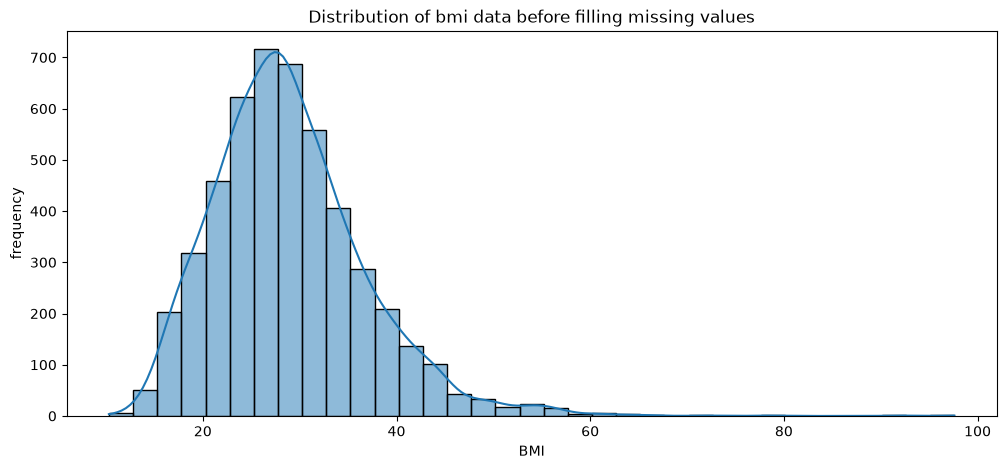

In [17]:
plt.figure(figsize=(12, 5))
sns.histplot(df['bmi'], kde=True, bins = 35)
plt.xlabel("BMI")
plt.ylabel("frequency")
plt.title("Distribution of bmi data before filling missing values")
plt.show()

In [18]:
# Since from the histogram, i can seee that the data is skewed, i will impute the missing values by median.abs

df['bmi'] = df['bmi'].fillna(df['bmi'].median())

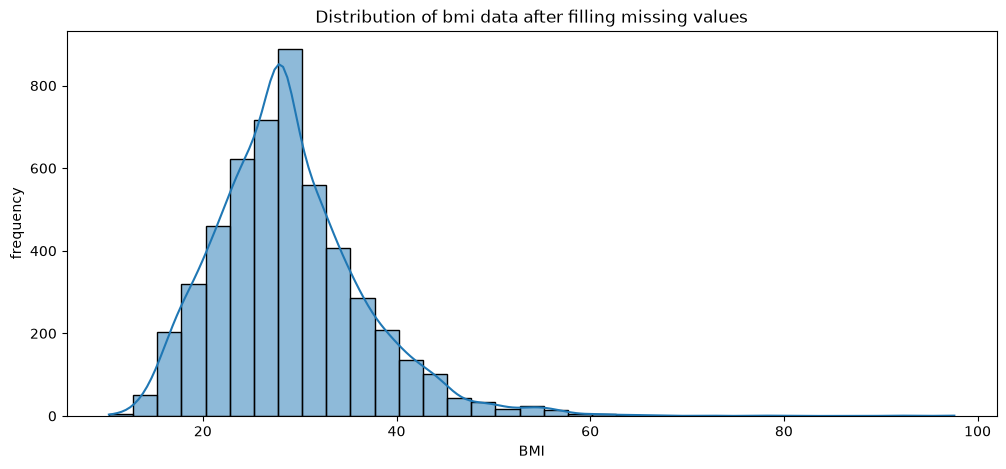

In [19]:
# Now i will check data distribution of bmi to ensure it remains same after imputation

# Using the same code as above --

plt.figure(figsize=(12, 5))
sns.histplot(df['bmi'], kde=True, bins = 35)
plt.xlabel("BMI")
plt.ylabel("frequency")
plt.title("Distribution of bmi data after filling missing values")
plt.show()

In [20]:
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [21]:
# Missing values have been handled and data distribution approximately same

In [22]:
# Dropping irrelevant features --

# patient-id is a feature which is irrelevant in determining whether a person has a stroke or not, so i am dropping it

df = df.drop(columns=['id'])
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [23]:
# NOTE: When i was doing feature-engineering after task-1, i got an error on gender feature
# ----  The error made me realize that there is one Irrelevant value in gender feature
# ---- So i am dropping it here.

df['gender'].value_counts()


gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

In [24]:
# The other value has no importance since its only 1 amoung 5000, so i am dropping it to resolve inconsistency b/w train and test set

df = df[df['gender'] != 'Other']

### Analyzing the class distribution --

In [25]:
df['stroke'].value_counts()

stroke
0    4860
1     249
Name: count, dtype: int64

In [26]:
df['stroke'].value_counts(normalize=True)*100 # finding the percentage occurence of each category

stroke
0    95.126248
1     4.873752
Name: proportion, dtype: float64

### High class Imbalance in dataset

- df shows a high class imbalance with only 4.8% people having a stroke
- this is common in medical datasets

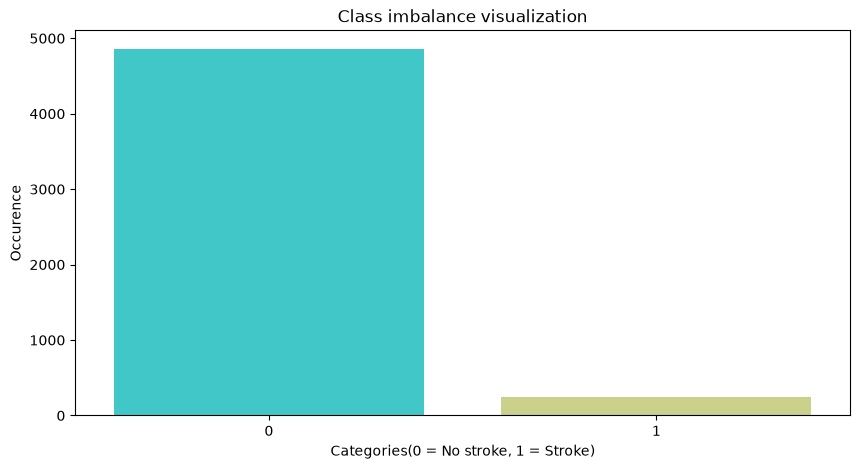

In [27]:
# i will make a countplot using seaborn to visualize this imbalance --

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x = 'stroke', palette='rainbow', hue = 'stroke', legend=False)
plt.title("Class imbalance visualization")
plt.xlabel("Categories(0 = No stroke, 1 = Stroke)")
plt.ylabel("Occurence")
plt.show()

### Analyzing correlations between numerical features

In [28]:
features_for_corr = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'stroke']

# hypertension, heart disease and stroke are categorical but since they are in the form of 0/1 binary in dataset and have int dtype,
# they can be used for correlation

In [29]:
correlation_matrix = df[features_for_corr].corr()
correlation_matrix

,age,avg_glucose_level,bmi,hypertension,heart_disease,stroke
age,1.000000,0.238323,0.324211,0.276367,0.263777,0.245239
avg_glucose_level,0.238323,1.000000,0.167033,0.174540,0.161907,0.131991
bmi,0.324211,0.167033,1.000000,0.158252,0.036879,0.036075
hypertension,0.276367,0.174540,0.158252,1.000000,0.108292,0.127891
heart_disease,0.263777,0.161907,0.036879,0.108292,1.000000,0.134905
stroke,0.245239,0.131991,0.036075,0.127891,0.134905,1.000000


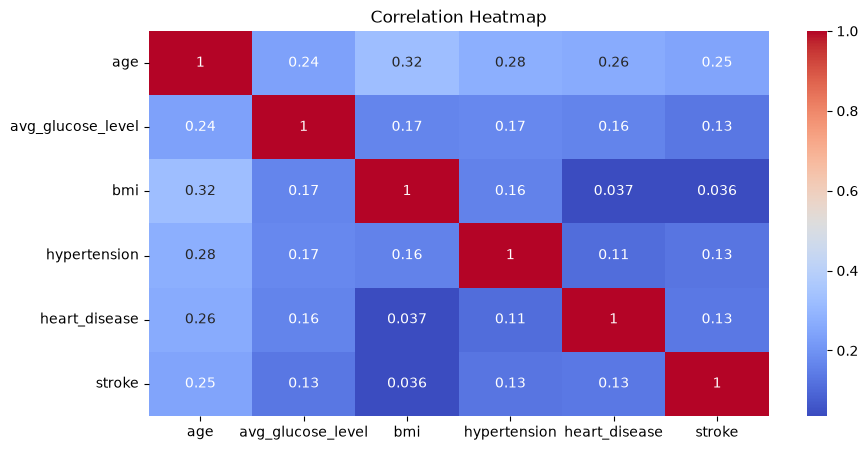

In [30]:
# Making a correlation heatmap to visualize correlation --

plt.figure(figsize=(10, 5))
sns.heatmap(correlation_matrix, annot=True, cmap = 'coolwarm')
plt.title("Correlation Heatmap")
plt.show()

### Observations from correlation analysis--

- 1-- As age increases, chances of having a stroke increase (+ve correlation -- 0.25)
- 2-- Also as age increases - bmi and risk of hypertension and heart disease increases(+ve correlations)
- 3-- Bmi has almost no correlation with stroke

# Checking for outliers in continous features

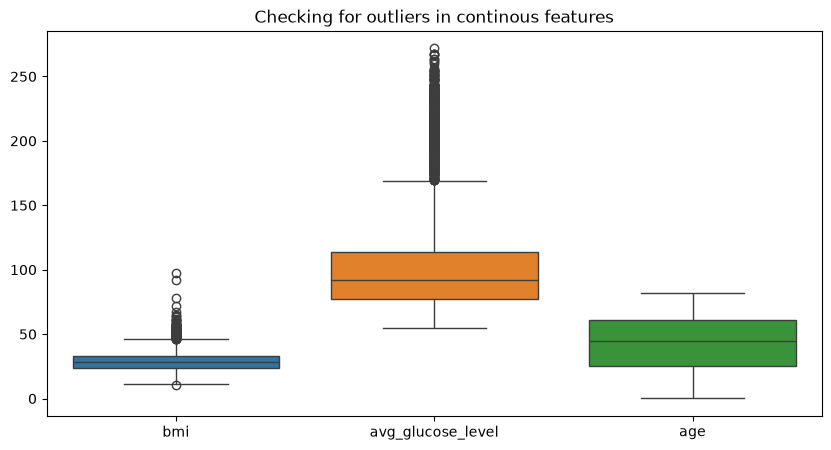

In [31]:
continous_features_data = df[['bmi', 'avg_glucose_level', 'age']]

plt.figure(figsize=(10, 5))
sns.boxplot(data = continous_features_data)
plt.title("Checking for outliers in continous features")
plt.show()

### Observations from outlier analysis --
 
- Bmi and avg glucose level features have a large no of outliers, while age has no outliers

In [32]:
# Since age was found to have the highest correlation with stroke, i am plotting a boxplot to visualize the age, stroke relationship

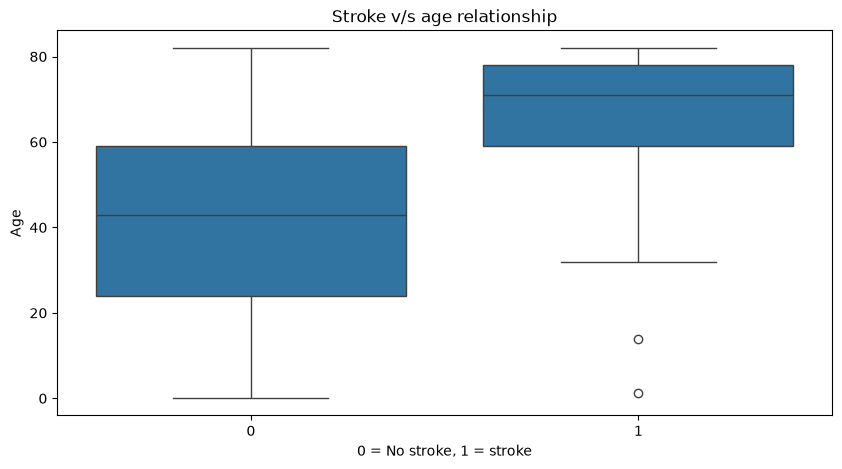

In [33]:
plt.figure(figsize=(10, 5))
sns.boxplot(data = df, x = 'stroke', y = 'age')
plt.title('Stroke v/s age relationship')
plt.xlabel('0 = No stroke, 1 = stroke')
plt.ylabel("Age")
plt.show()

In [34]:
# From the boxplot, its clear that people who got a stroke have a high age showing that with age chances of getting a stroke increases.. 


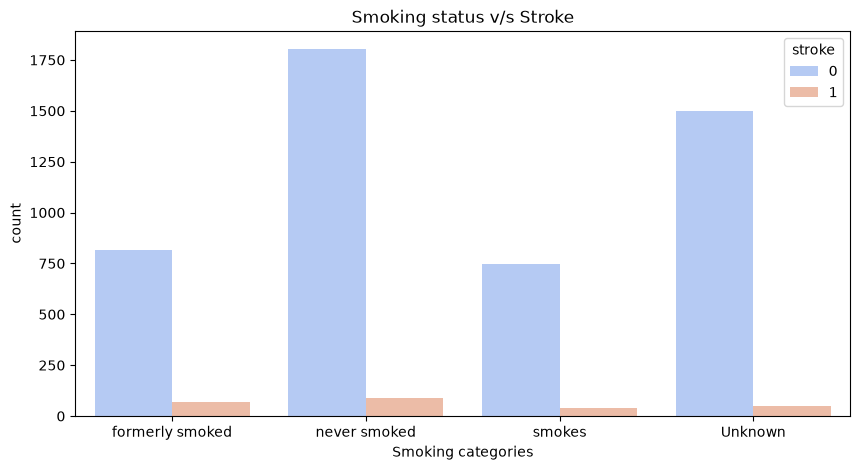

In [35]:
# Finding the relationship between smoking and stroke --

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x = 'smoking_status', hue = 'stroke', palette='coolwarm')
plt.title("Smoking status v/s Stroke")
plt.xlabel("Smoking categories")
plt.show()

In [36]:
# The above countplot shows that even among those who smoke, the stroke count is less.
# As this might be due to class imbalance, i will plot a countplot for only those who smoke to verify

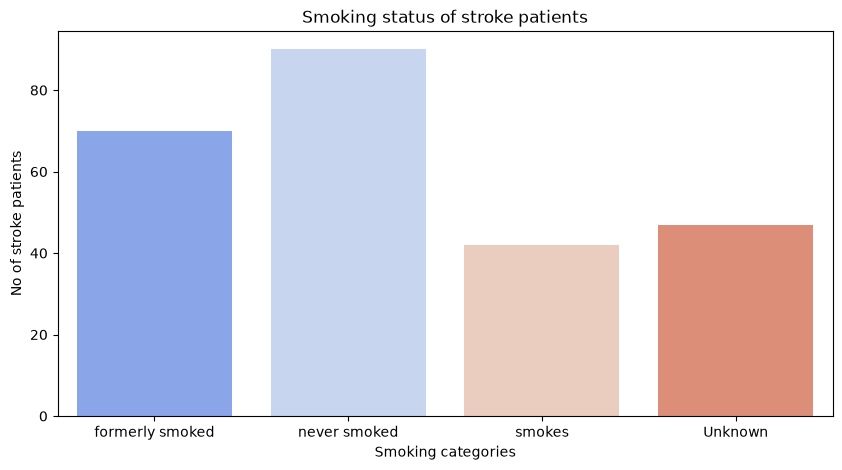

In [37]:
smokers = df[df['stroke'] == 1]

plt.figure(figsize=(10, 5))
sns.countplot(data = smokers, x = 'smoking_status', palette='coolwarm', hue = 'smoking_status', legend=False)
plt.title("Smoking status of stroke patients")
plt.xlabel("Smoking categories")
plt.ylabel("No of stroke patients")
plt.show()

In [38]:
# The above countplot shows that those who never smoked have high risk of having a stroke.
# But this might be due to imbalance in the smoking_status class --

df['smoking_status'].value_counts(normalize=True)*100

smoking_status
never smoked       37.032687
Unknown            30.221178
formerly smoked    17.302799
smokes             15.443335
Name: proportion, dtype: float64

In [39]:
# Due to the majority of people having unknown and never smoked status we cant trust the countplot results.

In [40]:
# Taking the mean of each smoking category to find the true relationship(currently affected by class imbalance)

stroke_by_smoking = df.groupby('smoking_status')['stroke'].mean() * 100
stroke_by_smoking

smoking_status
Unknown            3.044041
formerly smoked    7.918552
never smoked       4.756871
smokes             5.323194
Name: stroke, dtype: float64

In [41]:
# Around 7% of people who formerly smoked and 5% of those who smoke currently had a stroke which shows that
# smoking does increase the risk of having a stroke

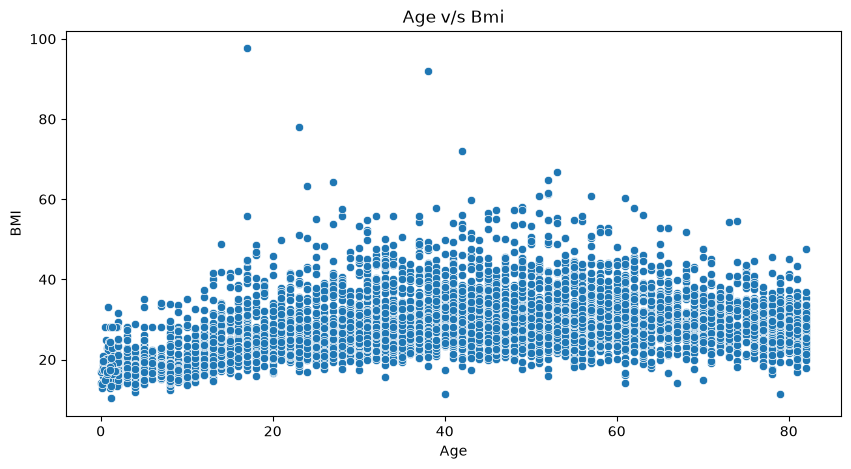

In [42]:
# Forming a scatter-plot to find relationship between age and bmi

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x = 'age', y = 'bmi')
plt.title('Age v/s Bmi')
plt.xlabel('Age')
plt.ylabel('BMI')
plt.show()

In [43]:
# In childhood, (age - 0-15), bmi values are clustered in a lower region as compared to the age group(20-60)
# Also, a lot of outliers can be seen in this scatterplot

## Work done till now on stroke-dataset

- First i used df.info() and df.describe() to understand the dataset
- I handled missing values using median imputation (i ensured that data distribution remains same)
- I formed a countplot to visualize class imbalance and found that dataset is highly imbalanced
- I also did outlier analysis using a boxplot
- I found the relationship between age and bmi using a scatterplot
- I formed a correlation heatmap and found that with age chances of having a stroke increases
- I analyzed the smoking_status feature and concluded that smoking increases the risk of stroke

## Conclusions from EDA

- Severe class imbalance in dataset (95% = No, 5% = Yes)
- A large number of outliers in bmi and average glucose level features
- With age, risk of having a stroke increases(from correlation heatmap and boxplot)
- Smoking increases the risk of having a stroke
- With age, bmi increases(from scatterplot)
- With hypertension or history of heart disease also, risk of having a stroke increases [+ve correlation]

- Age is seen as the most major factor behind stroke

## Reasoning

### q1 --  What problem does this dataset represent?
 
- Answer = This dataset represents a binary classification problem(target variable = stroke(yes / no)). Through this dataset i analyzed the reasons behind stroke and classification models can be built on this dataset which will predict whether a person will get a stroke or not

### q2 -- What output would be useful in the real world?

- Answer = The outputs(insights) we get from EDA can be useful in the real world. It will help people to identify the reasons behind stroke more clearly and efficiently. Also the model trained efficiently on this dataset can help predict someone getting a stroke before its too late and save someone's life.

### q3 --  Which features appear most useful and why?

- Answer = In this dataset, the features (age, hypertension, heart_disease, glucose level and smoking status) seem to be the most useful. This is because from the correlation heatmap and EDA Analysis we can clearly see that these features have the highest correlation with stroke and thus are major parameters which can indicate stroke in real world. On the other hand, bmi had negligible correlation with stroke, thus not having much importance in dataset's main aim.

### q4 -- What data-quality issues did you identify?

- Answer = The most major data quality issue which i identified in this dataset is Class Imbalance. Due to severe class imbalance in the dataset, it was difficult to uncover the relationship between smoking status and stroke due to this class imbalance due to results being affected by class imbalance. Apart from class imbalance, data had some missing values which i handled using median imputation.

### q5 -- What preprocessing steps are required before modelling?

- Answer = Before modelling, we need to take the following steps in this dataset:

1 => Handling missing values

2 => Encoding of categorical features like ever_married, gender, smoking_status (as models can only read numbers)

3 => Also feature scaling is required for some classification algorithms like Logistic Regression

### q6 -- What important pattern did you discover during EDA?

- Answer = The most important pattern i discovered during EDA was the relationship between age and stroke.

- Through my analysis i can conclude that younger people are less likely to have a stroke than old people.
- Also, hypertension, heart disease and smoking can be major reasons behind a stroke

In [44]:
#---------------------------------#

# Task-2:   Classification & Model Comparison

**For this task, i will use the same dataset i used for task1**

In [45]:
# Dataset after EDA

df.head(10)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,Female,59.0,0,0,Yes,Private,Rural,76.15,28.1,Unknown,1
9,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


### Models which i will be using to predict stroke/no-stroke --

- Logistic Regression
- Decision Tree Classifier

### Feature-Engineering(preparing the data so that it can be given to model)

- Encoding categorical features(gender, ever_married, work_type, residence_type, smoking_status)
- Scaling age, glucose_level, bmi(importnat for logistic reg.)

In [46]:
# Importing the libraries, modules required for task2 --

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

**train-test-split**

In [47]:
X = df.drop(columns=['stroke'])
y = df['stroke']

test_size = 0.20 + ((seed % 3) * 0.05)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = test_size, random_state = 42, stratify=y)

#stratify = y [so that proportions of target variable is same in train and test set]

In [48]:
X_train.shape, X_test.shape

((4087, 10), (1022, 10))

In [49]:
y_train.shape, y_test.shape

((4087,), (1022,))

In [50]:
# 1-- Encoding categorical features and performing standard scaling

# I will use one-hot-encoder since categorical features are nominal, if they were ordinal i would have used Ordinal Encoder
# I am using Standard Scalar for feature-scaling

In [51]:
tf = ColumnTransformer([
    ('tf1', OneHotEncoder(sparse_output=False, dtype=np.int32, drop = 'first'), ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']),
    ('tf2', StandardScaler(), ['age', 'avg_glucose_level', 'bmi'])
], remainder = 'passthrough')

In [52]:
# X_train_transformed = tf.fit_transform(X_train)
# X_test_transformed = tf.transform(X_test)

# The above code resulted in an error -- due to age feature

# now fixed above -- in task1

In [53]:
tf.set_output(transform='pandas') # this code will ensure that a df is returned instead of np array from fit_transform and transform

X_train_transformed = tf.fit_transform(X_train)
X_test_transformed = tf.transform(X_test)

In [54]:
X_train_transformed

,tf1__gender_Male,tf1__ever_married_Yes,tf1__work_type_Never_worked,tf1__work_type_Private,tf1__work_type_Self-employed,tf1__work_type_children,tf1__Residence_type_Urban,tf1__smoking_status_formerly smoked,tf1__smoking_status_never smoked,tf1__smoking_status_smokes,tf2__age,tf2__avg_glucose_level,tf2__bmi,remainder__hypertension,remainder__heart_disease
845,0,1,0,1,0,0,1,0,1,0,0.209397,-0.821221,0.549234,0,0
3745,0,0,0,1,0,0,1,0,1,0,-0.629845,-0.485884,-0.988900,0,0
4184,0,1,0,1,0,0,0,0,1,0,-0.364822,0.302317,-0.769166,0,0
3410,1,1,0,1,0,0,0,0,1,0,-0.232310,0.062342,0.497532,0,0
284,1,0,0,0,0,0,1,0,0,0,-1.292405,-0.527297,0.355351,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1434,0,1,0,1,0,0,1,1,0,0,0.076885,-0.291800,0.807744,0,0
461,0,0,0,0,0,1,0,0,0,0,-1.204064,0.169570,-1.208633,0,0
1052,0,1,0,1,0,0,0,1,0,0,0.783615,-0.609900,0.949924,0,0
1757,1,1,0,1,0,0,1,0,0,0,-0.541504,-0.712875,-0.368476,0,0


In [55]:
X_test_transformed

,tf1__gender_Male,tf1__ever_married_Yes,tf1__work_type_Never_worked,tf1__work_type_Private,tf1__work_type_Self-employed,tf1__work_type_children,tf1__Residence_type_Urban,tf1__smoking_status_formerly smoked,tf1__smoking_status_never smoked,tf1__smoking_status_smokes,tf2__age,tf2__avg_glucose_level,tf2__bmi,remainder__hypertension,remainder__heart_disease
3667,0,1,0,0,0,0,0,0,1,0,-0.674016,-0.497748,0.975775,1,0
2217,0,0,0,0,0,1,1,0,0,0,-1.778282,-0.281950,-1.208633,0,0
374,0,1,0,0,0,0,0,0,0,1,0.430250,-0.928896,0.277798,0,0
2392,1,1,0,1,0,0,0,0,1,0,-0.364822,-0.820997,1.803007,0,0
299,0,1,0,1,0,0,0,0,0,0,0.651103,-0.259564,0.032214,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2083,0,0,0,1,0,0,1,0,0,1,-0.850699,0.029659,0.833595,1,0
668,0,0,0,1,0,0,0,1,0,0,0.209397,0.274111,-0.097041,1,0
4381,0,0,0,0,1,0,1,0,0,0,-0.276480,-0.339929,2.190771,0,0
2514,1,0,0,1,0,0,1,0,0,0,-1.115722,-0.594230,-0.678688,0,0


**Data prepared to give to model, feature-engineering done**

**Training the logistic regression model**

In [56]:
model1 = LogisticRegression(class_weight='balanced', random_state=42)
# class wt = balanced, helps to increase the recall(which is desirable)

model1.fit(X_train_transformed, y_train) #model trained

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default

In [57]:
predictions = model1.predict(X_test_transformed)

In [58]:
# importing modules from sklearn used for evaluation 

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [59]:
# Classification report --
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.99      0.74      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



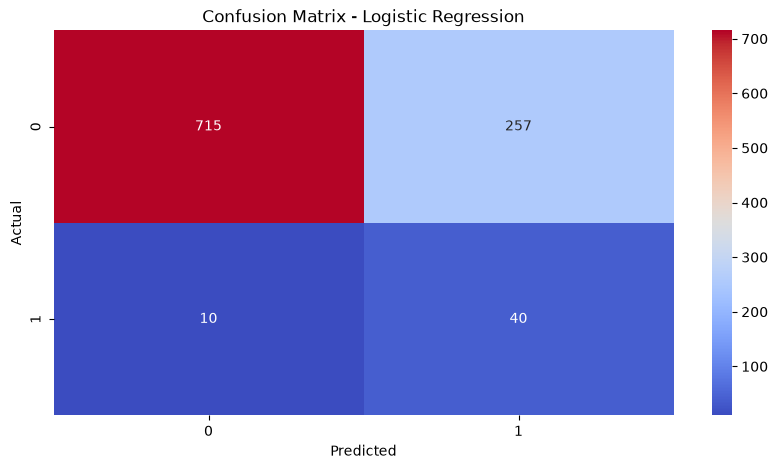

In [60]:
# plotting the confusion matrix

cm_matrix = confusion_matrix(y_test, predictions)

plt.figure(figsize=(10, 5))
sns.heatmap(cm_matrix, annot=True, cmap = 'coolwarm', fmt = 'd')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [61]:
cm_matrix

array([[715, 257],
       [ 10,  40]])

**Training the decision-tree model**

In [62]:
# Data has already been prepared by feature-engineering

In [63]:
# Decision-tree depth --

max_depth = 2 + (seed % 5)

model2 = DecisionTreeClassifier(class_weight='balanced', max_depth=max_depth, random_state=42)


In [64]:
#training --

model2.fit(X_train_transformed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are con

In [65]:
# predicting --

prediction_2 = model2.predict(X_test_transformed)

In [66]:
print(classification_report(y_test, prediction_2))

              precision    recall  f1-score   support

           0       0.99      0.55      0.71       972
           1       0.09      0.84      0.16        50

    accuracy                           0.57      1022
   macro avg       0.54      0.70      0.43      1022
weighted avg       0.94      0.57      0.68      1022



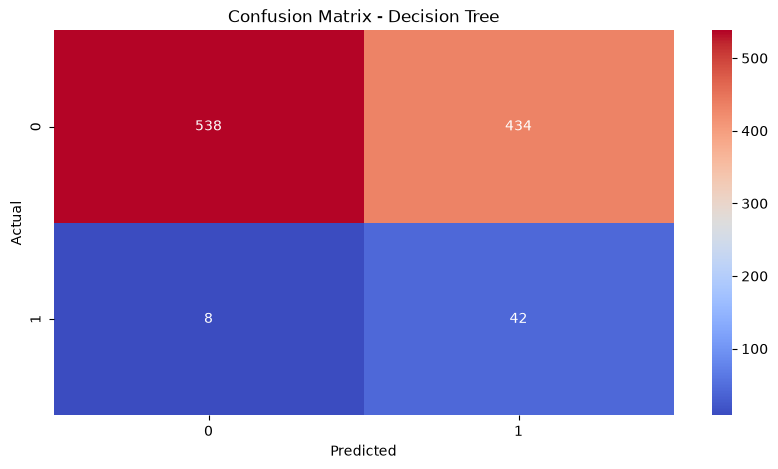

In [67]:
# Confusion matrix

cm_2 = confusion_matrix(y_test, prediction_2)

plt.figure(figsize=(10, 5))
sns.heatmap(cm_2, annot=True, fmt='d', cmap='coolwarm')
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [68]:
cm_2

array([[538, 434],
       [  8,  42]])

### Comparison table (Logistic Regression v/s Decision Tree)

| Model | Accuracy | Precision | Recall | F1-score |
| :--- | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 0.74 | 0.13 | 0.80 | 0.23 |
| **Decision Tree** | 0.57 | 0.09 | 0.84 | 0.16 |

## Observations and Final conclusions

### Precision v/s Recall

- Throughout the process, i realized that in medical datasets its very important to have a high recall. Identifying someone healthy to have a stroke is much less risky than identifying who is ill to not have a stroke. That's why i used class_weight = 'balanced' while training both the models, as i wanted recall to be high which is desirable in medical ML models

### Decision tree v/s logistic regression

- Recall of Decision tree and logistic regression models are comparable, but accuracy of decision tree model is very low as compared to logistic regression, so i think that Logistic Regression has performed better than decision tree in this case

## Reasoning

### q1 -- Which model performed better overall?

- Answer = Logistic Regression performed better than Decision Tree due to high accuracy as well as high recall. The accuracy of decision tree is very low while recall is comparable.

### q2 -- Did one model perform better on precision while another performed better on recall?

- Answer = Since this was a medical problem, i main focus was on increasing the recall. So both the models performed very bad on precision, while they performed very good on recall. This happened because i used class_weight = balanced while training the models.

- If i compare the raw numbers, then YES - logistic regression was better in precision while decision tree was better in recall

### q3 -- Was accuracy alone sufficient to judge the models?

- Answer = No, in this case the recall was the major factor to judge the performance of models. Predicting a sick person to be sick is our topmost priority in medical cases, so that proper and efficient treatment can be given to the person.

### q4 -- What does the confusion matrix reveal about the errors?

- Answer = Confusion matrix reveals that both the models were good predicting sick people as sick, but were very poor in predicting a healthy person to be healthy. Correctly predicting a sick person was my top priority, but still in future i will try to learn how i could have done better to make a model with good precision as well, as falsely identify a healthy person as sick also creates a lot of inconvenience

### q5 --  Is there any evidence of overfitting or underfitting?

- Answer = Yes, there is some evidence of underfitting (especially in decision tree), both the models have shown a very low f1score which indicates that they haven't understood the patterns in data that well. Class imbalance might have made difficult for the model to understand the patterns in minority class. I think if the data was more balanced outputs could be better.
### q6 -- Which model would you choose for the real-world problem and why?

- Answer = For the real world problem, i will choose Logistic regression as it is more accurate and also identifies a sick person correctly in 80% of cases. The decision tree might be very inconvenient in real world as it will keep identifying people incorrectly.

### Key Learnings 

- I understood how to use class_weight=balanced to increase recall
- I understood the importance of stratify = y so that train test split is done fairly
- I learnt how to build classification models, evaluate them and also how to find the better model

# Task-3: Regression & Prediction Analysis

**Dataset-Source**

The dataset used for this task has been taken from Kaggle

Dataset Link -- https://www.kaggle.com/datasets/camnugent/california-housing-prices

In [69]:
# Storing data in df

df_housing = pd.read_csv("data/housing.csv")

In [70]:
df_housing.head(10) #first 10 rows

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


**Input Features**  
latitude, longitude, housing_median_age, total rooms, total bedrooms, population, households, median_income and ocean-proximity

**Target Variable**  
median_house_value(continous label)

In [71]:
df_housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [72]:
df_housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [73]:
df_housing.shape

(20640, 10)

In [74]:
df_housing.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [75]:
df_housing.duplicated().sum()

np.int64(0)

In [76]:
df_housing['ocean_proximity'].value_counts() #checking the categories inside categorical feature

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [77]:
# There are 207 missing values in total_bedrooms and 0 duplicate rows

# data-cleaning -- involves handling missing values

**Data-cleaning**

**handling missing values**

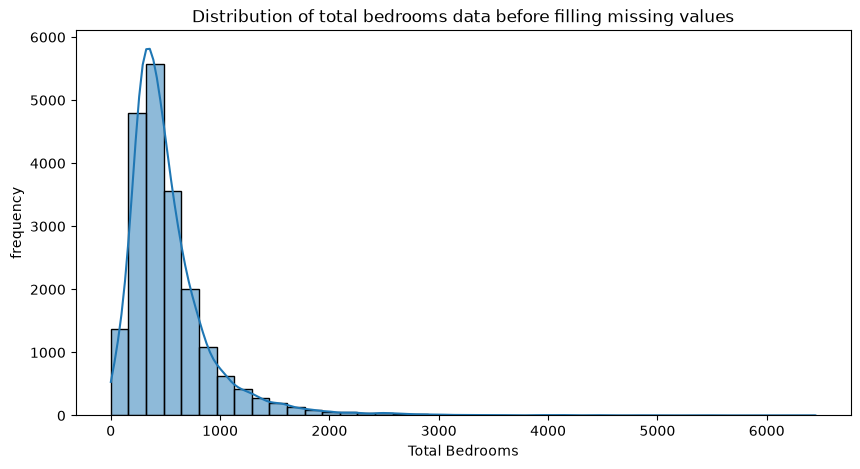

In [78]:
# checking the distribution of data in total_bedrooms feature

plt.figure(figsize=(10, 5))
sns.histplot(df_housing['total_bedrooms'], kde=True, bins = 40)
plt.title("Distribution of total bedrooms data before filling missing values")
plt.xlabel("Total Bedrooms")
plt.ylabel("frequency")
plt.show()

In [79]:
# As the data is right-skewed, i will impute the missing vals by median

df_housing['total_bedrooms'] = df_housing['total_bedrooms'].fillna(df_housing['total_bedrooms'].median())

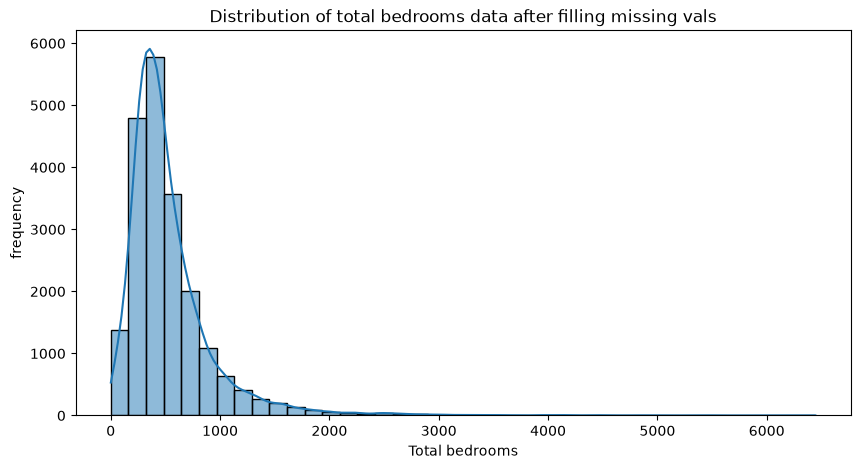

In [80]:
# Ensuring that data distribution remains same after filling missing values

plt.figure(figsize=(10, 5))
sns.histplot(df_housing['total_bedrooms'], kde= True, bins = 40)
plt.title("Distribution of total bedrooms data after filling missing vals")
plt.xlabel("Total bedrooms")
plt.ylabel("frequency")
plt.show()

In [81]:
df_housing.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [82]:
df_housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [83]:
# missing values have been filled

**train-test-split**

In [84]:
X_housing = df_housing.drop(columns=['median_house_value'])
y_housing = df_housing['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X_housing, y_housing, test_size=0.2, random_state=42)

**feature-engineering**

In [85]:
# Standard scalar to numerical features
# One-hot encoder for encoding categorical features

In [86]:
tf_housing = ColumnTransformer([
    ('tf1', StandardScaler(), [0, 1, 2, 3, 4, 5, 6, 7]),
    ('tf2', OneHotEncoder(sparse_output=False, dtype = np.int32, drop= 'first'), ['ocean_proximity'])
], remainder = 'passthrough')

In [87]:
tf_housing.set_output(transform='pandas') #so that output is df instead of np array

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tf1', ...), ('tf2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

In [88]:
X_train_transformed = tf_housing.fit_transform(X_train)
X_test_transformed = tf_housing.transform(X_test)

In [89]:
X_train_transformed.head()

,tf1__longitude,tf1__latitude,tf1__housing_median_age,tf1__total_rooms,tf1__total_bedrooms,tf1__population,tf1__households,tf1__median_income,tf2__ocean_proximity_INLAND,tf2__ocean_proximity_ISLAND,tf2__ocean_proximity_NEAR BAY,tf2__ocean_proximity_NEAR OCEAN
14196,1.272587,-1.372811,0.348490,0.222569,0.211228,0.768276,0.322906,-0.326196,0,0,0,1
8267,0.709162,-0.876696,1.618118,0.340293,0.593094,-0.098901,0.672027,-0.035843,0,0,0,1
17445,-0.447603,-0.460146,-1.952710,-0.342597,-0.495226,-0.449818,-0.430461,0.144701,0,0,0,1
14265,1.232698,-1.382172,0.586545,-0.561490,-0.409306,-0.007434,-0.380587,-1.017864,0,0,0,1
2271,-0.108551,0.532084,1.142008,-0.119565,-0.256559,-0.485877,-0.314962,-0.171488,1,0,0,0


In [90]:
# Feature-engineering done

**Training the baseline model on linear regression using all features**

In [91]:
# importing required modules from sklearn

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [92]:
model_regression = LinearRegression()

In [93]:
#training --

model_regression.fit(X_train_transformed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[-53826.65,-54415.7 , 13889.87,...,136125.07, -5136.64, 3431.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['tf1__longitude','tf1__latitude','tf1__housing_median_age',..., 'tf2__ocean_proximity_ISLAND','tf2__ocean_proximity_NEAR BAY', 'tf2__ocean_proximity_NEAR OCEAN']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.199e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [94]:
# Predicting --

predictions_regression = model_regression.predict(X_test_transformed)

In [95]:
# evaluating --

mae = mean_absolute_error(y_test, predictions_regression)
mse = mean_squared_error(y_test, predictions_regression)
rmse = root_mean_squared_error(y_test, predictions_regression) #can also have done np.sqrt(mse) as rmse is root of mse
r2 = r2_score(y_test, predictions_regression)

In [96]:
# Printing the results --

print(f'MAE = {mae}')
print(f'MSE = {mse}')
print(f'RMSE = {rmse}')
print(f'R2 Score = {r2}')

MAE = 50670.738240971885
MSE = 4908476721.156619
RMSE = 70060.52184473521
R2 Score = 0.6254240620553604


**Doing the personalized feature experiment**

In [97]:
features = list(X_housing.columns)
feature_to_drop = features[seed % len(features)]
print("Personalised feature to drop:", feature_to_drop)

Personalised feature to drop: total_rooms


In [98]:
X_train_new = X_train.drop(columns=[feature_to_drop])
X_test_new = X_test.drop(columns=[feature_to_drop])

**Doing feature-engineering on new X_train, X_test**

In [99]:
X_train_new.head()

,longitude,latitude,housing_median_age,total_bedrooms,population,households,median_income,ocean_proximity
14196,-117.03,32.71,33.0,627.0,2300.0,623.0,3.2596,NEAR OCEAN
8267,-118.16,33.77,49.0,787.0,1314.0,756.0,3.8125,NEAR OCEAN
17445,-120.48,34.66,4.0,331.0,915.0,336.0,4.1563,NEAR OCEAN
14265,-117.11,32.69,36.0,367.0,1418.0,355.0,1.9425,NEAR OCEAN
2271,-119.80,36.78,43.0,431.0,874.0,380.0,3.5542,INLAND


In [100]:
tf_housing_new = ColumnTransformer([
    ('tf1', StandardScaler(), [0, 1, 2, 3, 4, 5, 6]),
    ('tf2', OneHotEncoder(sparse_output=False, dtype = np.int32, drop= 'first'), ['ocean_proximity'])
], remainder = 'passthrough')

In [101]:
tf_housing_new.set_output(transform='pandas')

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tf1', ...), ('tf2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

In [102]:
X_train_transformed_new = tf_housing_new.fit_transform(X_train_new)
X_test_transformed_new = tf_housing_new.transform(X_test_new)

In [103]:
X_train_transformed_new

,tf1__longitude,tf1__latitude,tf1__housing_median_age,tf1__total_bedrooms,tf1__population,tf1__households,tf1__median_income,tf2__ocean_proximity_INLAND,tf2__ocean_proximity_ISLAND,tf2__ocean_proximity_NEAR BAY,tf2__ocean_proximity_NEAR OCEAN
14196,1.272587,-1.372811,0.348490,0.211228,0.768276,0.322906,-0.326196,0,0,0,1
8267,0.709162,-0.876696,1.618118,0.593094,-0.098901,0.672027,-0.035843,0,0,0,1
17445,-0.447603,-0.460146,-1.952710,-0.495226,-0.449818,-0.430461,0.144701,0,0,0,1
14265,1.232698,-1.382172,0.586545,-0.409306,-0.007434,-0.380587,-1.017864,0,0,0,1
2271,-0.108551,0.532084,1.142008,-0.256559,-0.485877,-0.314962,-0.171488,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
11284,0.808883,-0.872016,0.507194,-0.805492,-0.675847,-0.742833,1.307215,0,0,0,0
11964,1.073144,-0.759688,0.348490,0.075188,0.287195,-0.133839,-0.436266,1,0,0,0
5390,0.599469,-0.755007,0.586545,0.072801,0.289833,0.070909,-0.496973,0,0,0,0
860,-1.185540,0.906510,-1.079841,0.139628,0.308303,0.154908,0.965450,0,0,0,0


In [104]:
model_regression_new = LinearRegression()

In [105]:
#training --

model_regression_new.fit(X_train_transformed_new, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[-54792.78,-55723.58, 14082.05,...,135097.33, -5556.52, 2668.88]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['tf1__longitude','tf1__latitude','tf1__housing_median_age',..., 'tf2__ocean_proximity_ISLAND','tf2__ocean_proximity_NEAR BAY', 'tf2__ocean_proximity_NEAR OCEAN']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.206e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [106]:
#predicting 

predictions_regression_new = model_regression_new.predict(X_test_transformed_new)

In [107]:
#evaluating --

mae_new = mean_absolute_error(y_test, predictions_regression_new)
mse_new = mean_squared_error(y_test, predictions_regression_new)
rmse_new = root_mean_squared_error(y_test, predictions_regression_new) #can also have done np.sqrt(mse) as rmse is root of mse
r2_new = r2_score(y_test, predictions_regression_new)

In [108]:
# printing the results --

print(f'MAE = {mae_new}')
print(f'MSE = {mse_new}')
print(f'RMSE = {rmse_new}')
print(f'R2 Score = {r2_new}')

MAE = 50675.61031029932
MSE = 4887966108.2883005
RMSE = 69913.99079074446
R2 Score = 0.6269892690410338


### Visualizing the actual v/s predicated values using a scatter plot.
- (plotting graphs for both the model trained on all features and the model trained on reduced data)

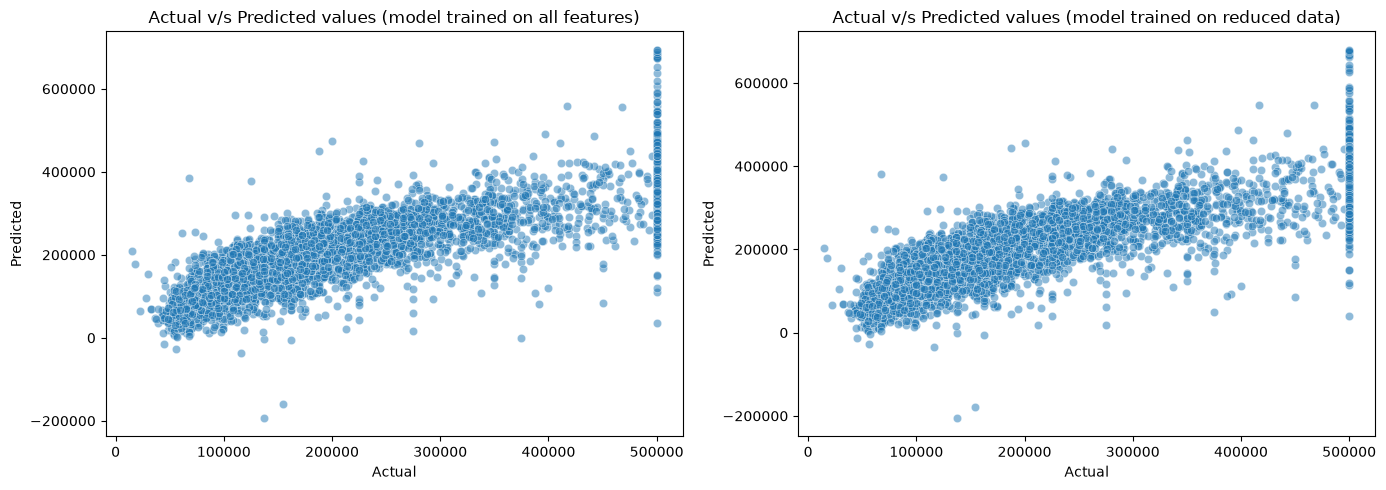

In [109]:
fig, axes = plt.subplots(1, 2, figsize= (14, 5)) #this code helps in forming side by side figures

sns.scatterplot(x = y_test, y = predictions_regression, alpha = 0.5, ax = axes[0])
axes[0].set_title("Actual v/s Predicted values (model trained on all features)")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

sns.scatterplot(x = y_test, y = predictions_regression_new, alpha = 0.5, ax = axes[1])
axes[1].set_title("Actual v/s Predicted values (model trained on reduced data)")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")

plt.tight_layout()
plt.show()

## Question -- How did dropping the personalized feature affect predictive model performance??

#### Answer - I dropped the total_rooms feature and dropping this feature slightly imporved the models' performance as the r2 score got increased slightly. This happened because i think the total rooms feature was redundant as total bedrooms feature already exists to indicate the number of rooms. Dropping total bedrooms instead of total rooms would also have increased the models performance.

## Reasoning

### q1 -- What does each regression metric tell you?

- Answer = MAE is the average error between actual and predicted values, MSE squares the errors(thus unit is converted to dollar-squared and it penalizes large erros more heavily.) RMSE is root of MSE and doesnt penalize large errors as heavily as MSE, R2-score tells how much of the variance in predictions is explained by the model

### q2 -- How close are the predictions to the actual values?

- Answer = From the scatterplots of actual v/s predicted values -- we can see that for lower values of house price, model follows a line and performs reasonably well, but for large values the line falls. As MAE is around 50k it shows that predictions are on average off by 50k from actual.

### q3 -- What does the R² score indicate about the model?

- Answer = R2 score indicates how much of the variance between actual and predicted values the model can actually explain. In this case, i got a variance near to 62.5%, this shows that 37.5 % of variances cant be explained by the model.

### q4 -- Did removing the personalised feature improve or reduce performance?

- Answer = Yes, removing the personalized feature(total_rooms) imporved the model's performance slightly. this happened because it was a redundant feature as total_bedrooms is already there.

### q5 -- Which features appear to have the strongest relationship with the target?

- Answer = Among the features in the dataset, median_income, ocean_proximity and location(latitude, longitude) seem to play a strong role in predicting the target. Features like total_rooms are not that important as compared to these features.

### q6 -- What could you do to improve the model?

- Answer = I think a lot of outliers were there in this dataset, so handling those outliers can imporve the performance. Also training on non-linear models like random forest etc. can help me capture the relationships more efficiently. Forming new features like rooms per household etc. can help me form better features (so better feature engineering can be done to improve the performance)

### Observations and Conclusions

- Linear Regression achieved an R² score of 62.5, explaining about 62.5% of variance in house prices
- The model performs reasonably for low-to-mid range house values but underpredicts for expensive houses
- Dropping the personalised feature (`total_rooms`) had negligible impact on performance, suggesting feature redundancy
- `median_income` is the most important predictor of house value, followed by geographic features
- A linear model has limitations for this problem,non-linearmodels would likely perform better
- The MAE of 50,000 is significant and shows room for improvement
- Feature engineering (creating ratio features) and using more powerful algorithms are the most promising paths to improvement

# Task-4:  Unsupervised Learning & Clustering

**For this task i will be using the same dataset i used in task-3(regression)**

In [110]:
df_housing.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


### Feature-Selection

- I will use 4 features (longitude, latitude, median_income and housing_median_age) for clustering

In [111]:
features_clustering = ['longitude', 'latitude', 'housing_median_age', 'median_income']
X_clustering = df_housing[features_clustering].copy()

#i have stored the data of features selected for clustering in X_clustering

In [112]:
X_clustering

,longitude,latitude,housing_median_age,median_income
0,-122.23,37.88,41.0,8.3252
1,-122.22,37.86,21.0,8.3014
2,-122.24,37.85,52.0,7.2574
3,-122.25,37.85,52.0,5.6431
4,-122.25,37.85,52.0,3.8462
...,...,...,...,...
20635,-121.09,39.48,25.0,1.5603
20636,-121.21,39.49,18.0,2.5568
20637,-121.22,39.43,17.0,1.7000
20638,-121.32,39.43,18.0,1.8672


### Why i selected these 4 features for clustering?

- I chose these 4 features because these 4 features represent geography(latitude, longitude) and socio-economic situation of the neighbourhood which could directly affect house prices and help me form meaningful clusters

**Scaling X_clustering**

In [113]:
scalar_clustering = StandardScaler()
X_clustering_scaled = scalar_clustering.fit_transform(X_clustering)

In [114]:
X_clustering_scaled

array([[-1.32783522,  1.05254828,  0.98214266,  2.34476576],
       [-1.32284391,  1.04318455, -0.60701891,  2.33223796],
       [-1.33282653,  1.03850269,  1.85618152,  1.7826994 ],
       ...,
       [-0.8237132 ,  1.77823747, -0.92485123, -1.14259331],
       [-0.87362627,  1.77823747, -0.84539315, -1.05458292],
       [-0.83369581,  1.75014627, -1.00430931, -0.78012947]],
      shape=(20640, 4))

In [115]:
# Converting scaled np array to panda dataframe

df_clustering = pd.DataFrame(X_clustering_scaled, columns=features_clustering)
df_clustering

,longitude,latitude,housing_median_age,median_income
0,-1.327835,1.052548,0.982143,2.344766
1,-1.322844,1.043185,-0.607019,2.332238
2,-1.332827,1.038503,1.856182,1.782699
3,-1.337818,1.038503,1.856182,0.932968
4,-1.337818,1.038503,1.856182,-0.012881
...,...,...,...,...
20635,-0.758826,1.801647,-0.289187,-1.216128
20636,-0.818722,1.806329,-0.845393,-0.691593
20637,-0.823713,1.778237,-0.924851,-1.142593
20638,-0.873626,1.778237,-0.845393,-1.054583


In [116]:
# checking mean and standard deviation of final df prepared for clustering

df_clustering.describe().round()

,longitude,latitude,housing_median_age,median_income
count,20640.0,20640.0,20640.0,20640.0
mean,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0
min,-2.0,-1.0,-2.0,-2.0
25%,-1.0,-1.0,-1.0,-1.0
50%,1.0,-1.0,0.0,-0.0
75%,1.0,1.0,1.0,0.0
max,3.0,3.0,2.0,6.0


In [117]:
# mean = 0 and standard devition of 1 shows that standard scaling has occured

In [118]:
# importing required modules --

from sklearn.cluster import KMeans

**performing the elbow method**

In [119]:
inertia = []
values_of_k = range(1, 11)

for k in values_of_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_clustering_scaled)

    inertia.append(kmeans.inertia_) #shows how good clustering algo is performing

**plotting the elbow curve**

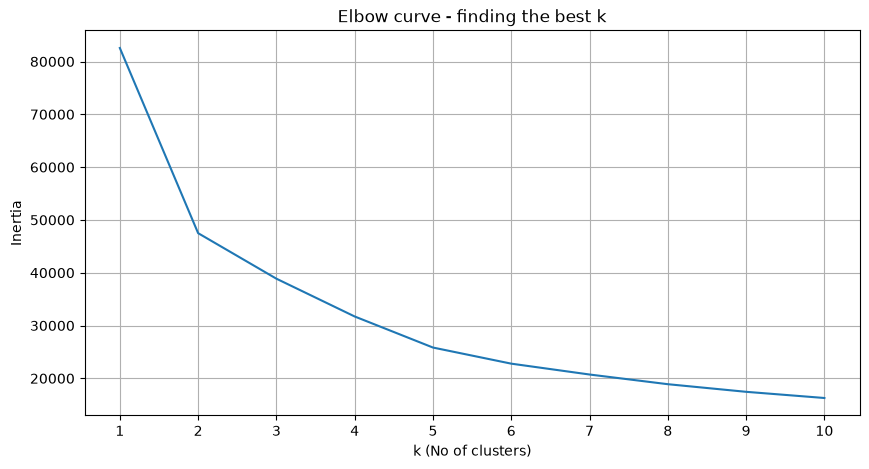

In [120]:
plt.figure(figsize=(10, 5))
plt.plot(values_of_k, inertia)
plt.title("Elbow curve - finding the best k")
plt.xlabel("k (No of clusters)")
plt.ylabel("Inertia") #sum of squared distances
plt.xticks(values_of_k)
plt.grid(True) #forms a grid
plt.show()

**From the elbow curve, the slope starts decreaing less(becomes gentle) around k = 5**

**I am forming a dataframe to see the change in inertia values and will choose k according to the difference in inertia values**

**This will help verifying my results, and will stop me from choosing k just by seeing a slope**

In [121]:
df_inertia = pd.DataFrame({
    'k' : values_of_k,
    'inertia' : inertia
})

df_inertia

,k,inertia
0,1,82560.000000
1,2,47493.833289
2,3,38871.431001
3,4,31715.493602
4,5,25832.208154
5,6,22781.331593
6,7,20725.353995
7,8,18891.589921
8,9,17448.626035
9,10,16278.132950


In [122]:
df_inertia['drop in inertia'] = df_inertia['inertia'].diff().abs()
df_inertia

,k,inertia,drop in inertia
0,1,82560.000000,NaN
1,2,47493.833289,35066.166711
2,3,38871.431001,8622.402288
3,4,31715.493602,7155.937400
4,5,25832.208154,5883.285448
5,6,22781.331593,3050.876560
6,7,20725.353995,2055.977598
7,8,18891.589921,1833.764073
8,9,17448.626035,1442.963886
9,10,16278.132950,1170.493085


**Value of k chosen from elbow curve and inertia results**

k = 5

From the elbow curve and the inertia drop analysis, i can see that the rate of decrease in inertia slows down significantly after k=5. The inertia drop from k=4 to k=5 is still noticeable, but from k=5 to k=6 the drop becomes much smaller — indicating diminishing returns. So k=5 is the "elbow point" where adding more clusters stops providing meaningful improvement.

i think that after k = 5, the drop in inertia becomes less significant.
Also k = 5 aligns with ocean proximity categories which could help me form clusters based on that

**Comparison with personalized value of k**

The personalised k (5) is the same as the k suggested by the elbow method. I didndt force myself to use the personalised k, the data itself showed that k=5 is the most appropriate choice through both the elbow curve and inertia analysis. This is a coincidence that strengthens confidence in k=5 being the right number of clusters for this data.

 #-----#

**Training scaled features on k = 5**

In [123]:
final_k = 5
kmeans_final = KMeans(n_clusters=final_k, random_state=42,   n_init=10)
kmeans_final.fit(X_clustering_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 4)","[[ 0.

In [124]:
# now i will add the cluster labels to the housing df

df_housing['clustering_labels'] = kmeans_final.labels_

In [125]:
df_housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,clustering_labels
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,1
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,1
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,3
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,3
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,3


**Now i will analkyze the characteristics of clusters**

In [126]:
cluster_summary = df_housing.groupby('clustering_labels')[['latitude', 'longitude', 'housing_median_age', 'median_income']].mean()
cluster_summary

,latitude,longitude,housing_median_age,median_income
clustering_labels,,,,
0,33.823496,-117.762780,17.074130,3.874440
1,34.876764,-119.197202,27.025365,8.710985
2,37.999410,-121.491473,18.448067,3.719924
3,37.917679,-121.953207,41.489061,3.379274
4,34.023292,-118.148855,37.183019,3.277161


**Observations after analyzing cluster info**

From the cluster summary table :
- **Cluster 0** (latitude ~33.8, longitude ~-117.8, age ~17, income ~3.87) — Southern California inland areas with newer housing and moderate income
- **Cluster 1** (latitude ~34.9, longitude ~-119.2, age ~27, income ~8.71) — Coastal/Santa Barbara region with high income — this is the wealthiest cluster by far
- **Cluster 2** (latitude ~38.0, lon ~-121.5, age ~18, income ~3.72) — Central/Northern California with newer housing and moderate income (likely Central Valley)
- **Cluster 3** (latitude ~37.9, lon ~-122.0, age ~41, income ~3.38) — San Francisco Bay Area with the oldest housing stock and moderate income
- **Cluster 4** (latitude ~34.0, lon ~-118.1, age ~37, income ~3.28) — Los Angeles metro area with older housing and the lowest average income

**Performing principal component analysis (pca)**

In [127]:
# importing pca from sklearn

from sklearn.decomposition import PCA

In [128]:
pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(X_clustering_scaled)

In [129]:
#forming dataframe after pca so that i can draw the graph later--

df_pca = pd.DataFrame(data = pca_results, columns=['pc1', 'pc2'])
df_pca['cluster'] = df_housing['clustering_labels'].values 
df_pca

,pc1,pc2,cluster
0,-1.625427,1.177104,1
1,-1.461255,2.268436,1
2,-1.738437,0.170332,3
3,-1.793623,-0.434444,3
4,-1.851143,-1.108067,3
...,...,...,...
20635,-1.843289,-0.463869,2
20636,-1.802606,0.300292,2
20637,-1.806097,0.032347,2
20638,-1.843597,0.043906,2


In [130]:
# finding which principal compenent(pc1, pc2) represents which feature

components_importance = pd.DataFrame(pca.components_, columns=features_clustering, index = ['pc1', 'pc2'])
components_importance

,longitude,latitude,housing_median_age,median_income
pc1,0.703414,-0.701437,-0.097445,0.060813
pc2,-0.079097,0.078706,-0.693061,0.712190


**Observations after seeing which component represents what**

- pc1 represents geography
- pc2 represents median_age and median_income

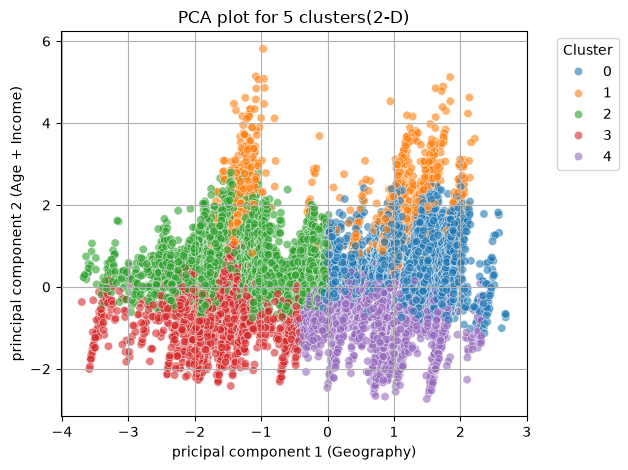

In [131]:
# forming the scatterplot

sns.scatterplot(x = 'pc1', y = 'pc2', data = df_pca, alpha = 0.6, hue = 'cluster', palette='tab10')
plt.title("PCA plot for 5 clusters(2-D)")
plt.xlabel("pricipal component 1 (Geography)")
plt.ylabel("principal component 2 (Age + Income)")
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

**What does each cluster represent?**

- **Cluster 0** — Newer suburban developments in Southern California (Orange County, Riverside area). Relatively new construction (avg age ~17 years) with moderate income.
- **Cluster 1** — Affluent coastal communities (Santa Barbara, Ventura). Stands out with the highest median income (~8.71),represents wealthy, established coastal areas.
- **Cluster 2** — Central Valley and Northern California. Newer housing (avg age ~18) with moderate incom, these are likely growing inland cities and agricultural areas.
- **Cluster 3** — San Francisco Bay Area. Has the oldest housing stock (avg age ~41 years) reflecting the established urban neighborhoods of SF and surrounding cities.
- **Cluster 4** — Greater Los Angeles area. Older housing (avg age ~37) with the lowest average income, represents the dense, urban core of LA.

In [132]:
# comparing the clusters to ocean_proximity

cluster_vs_proximity = pd.crosstab(df_housing['clustering_labels'], df_housing['ocean_proximity'])
cluster_vs_proximity

ocean_proximity,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
clustering_labels,,,,,
0,2441,1365,0,0,794
1,863,114,0,125,199
2,1029,2734,0,564,304
3,468,1184,0,1601,495
4,4335,1154,5,0,866


**Cluster v/s Ocean Proximity Analysis**

**Personalized - k**

In [133]:
k_personalised = 2 + (seed % 4)
k_personalised

5

In [134]:
# k which i took for analysis is same as k_personalized
# I didnt force myself to use the k same as k_personalized but the data itself showed the appropriate value of k to be 5 by elbow curve

### Observations and Conclusions

- K-Means with k=5 successfully discovered 5 meaningful clusters that correspond to real geographic and economic regions of California
- Feature scaling was critical , without it, longitude/latitude values (-122 to -114) would have dominated over median_income (0-15) due to their larger magnitude
- PCA revealed that PC1 captures geographic variation (longitude, latitude) while PC2 captures socio-economic variation (median_age, median_income)
- The clusters align well with the ocean_proximity labels even though these labels were never used during training — this confirms that the clustering captured genuine patterns
- Cluster 1 (high-income coastal areas) is the most distinct cluster, standing out clearly in both the cluster summary and PCA plot
- The elbow method and personalised k both pointed to k=5, providing strong confidence in the choice

### Reasoning

#### q1 -- Why was feature scaling required?
- Answer = Feature scaling was required because K-Means uses distance calculation between points to form clusters and if the values are not in the same scale.. large values coud affect the distance calculations and thus not forming good outputs/clusters.. 

#### q2 -- What did the Elbow Method suggest?
- Answer = The Elbow Method suggested k=5. The inertia (sum of squared distances from each point to its assigned cluster center) decreased sharply from k=1 to k=5, but after k=5 the decrease became much gentler. This "elbow" at k=5 indicates that adding more clusters beyond 5 provides diminishing improvement in clustering quality.

#### q3 -- How does the personalised k compare with the elbow result?
- Answer = The personalised k = 2 + (291 % 4) = 5, which is exactly the same as the value suggested by the Elbow Method. I did not force the personalised k — the data naturally pointed to k=5 as the best choice. This coincidence further validates that 5 clusters is the right number for this dataset.

#### q4 -- What does each final cluster appear to represent?
- Answer = Cluster 0 represents newer suburban developments in Southern California. Cluster 1 represents affluent coastal communities with high income. Cluster 2 represents Central Valley and Northern California's growing inland areas. Cluster 3 represents the established San Francisco Bay Area with old housing. Cluster 4 represents the dense, older neighborhoods of Greater Los Angeles. Each cluster has a distinct combination of geography, housing age, and income level.

#### q5 -- If labels exist, do the clusters match those labels? Why or why not?

- Answer = Yes, the clusters largely match the `ocean_proximity` labels. The crosstab analysis shows clear alignment — for example, Cluster 3 is dominated by NEAR BAY (matching Bay Area), Cluster 2 by INLAND (matching Central Valley), and Cluster 4 by <1H OCEAN (matching LA). The match is not perfect because ocean_proximity only captures one dimension (distance from ocean) while the clusters also account for income and housing age. But the strong overlap validates that K-Means discovered real geographic patterns.
#### q6 -- What real-world decision could be supported using these clusters?


- Answer = These clusters could support real estate investment decisions — for example, identifying undervalued areas by finding clusters with low median income but high geographic desirability. Urban planners could use the clusters to understand housing development patterns across California. Real estate companies could use them for targeted marketing — a luxury property campaign would focus on Cluster 1 (high income, coastal), while affordable housing initiatives would target Cluster 4 (older housing, lower income in LA). Insurance companies could also use geographic clusters for risk assessment.

# Task-5: Advanced AI Model Building

## Track chosen --

### Image classification using CNN

### Dataset used and source --

- I have used the fashion-MNIST dataset and importing it directly using pytorch into the data folder

**Importing required libraries**

In [135]:
import torch
import torch.optim as optim
import torch.nn as nn 
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import torch.nn.functional as F

**for the random operations of pytorch i will use my personalized seed**

In [136]:
torch.manual_seed(seed=seed)

In [137]:
#checking if my laptop has gpu or i will run the things on cpu ..

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [138]:
# i have installed the cpu version of pytorch.. so i will do task5 on cpu only

**defining image transformations [image pixels first scaled to [0,1] and then placed in a range of [-1, 1]]**

**This is done because neural networks work better when data is centered around 0**

**gray-scale images only have 1 color channel that's why only one 0.5 is used in code below**

In [139]:
img_transform = transforms.Compose([
    transforms.ToTensor(), #converts to tensor and scales in range of [0, 1]
    transforms.Normalize((0.5,), (0.5,)) #puts pixels in a range of [-1, 1]
])

**Downloading and Loading the FASHION-MNIST dataset**

In [140]:
# loading the training data

train_data = torchvision.datasets.FashionMNIST(
    root = './data',
    train=True,
    download=True,
    transform = img_transform
)

# loading the testing data

test_data = torchvision.datasets.FashionMNIST(
    root = './data',
    train=False,
    download=True,
    transform = img_transform
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 232kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.27MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [141]:
len(train_data), len(test_data)

(60000, 10000)

In [142]:
# 60,000 images in train data and 10k images in test data

**Now i will put 10k images form the train dataset into the validation dataset**

In [143]:
train_size = 50000
validation_size = 10000

train_dataset, validation_dataset = random_split(train_data, [train_size, validation_size])

In [144]:
len(train_dataset), len(validation_dataset), len(test_data)

(50000, 10000, 10000)

**Now i will wrap the data into a data loader, this will stop me from putting the whole 50k images to model at once**

**shuffle = True helps shuffling the images so that model doesnt memorize the order**

In [145]:
batch = 64
train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle= True)
validation_dataloader = DataLoader(validation_dataset, batch_size= batch, shuffle=False)
test_dataloader = DataLoader(test_data, batch_size=batch, shuffle=False)

**Now i will try to understand my data**

In [146]:
#grabbing the 1st image from a batch and seeing the number of color channels, width, height 

dataiter = iter(train_dataloader)
images, labels = next(dataiter)

print(images.shape)

torch.Size([64, 1, 28, 28])


In [147]:
# above data shows that there are 64 images in one batch, 1 color channel only (as its greyscle) a
# the image is 28 pixels wide and has a height of 28 pixels

In [148]:
# Defining the classes/categories in FASHION-MNIST

classes = ('T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat','Sandal', 'Shirt', 'Sneaker', 'Bag','Ankle boot')
classes

('T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot')

**Printing some images in train dataset**

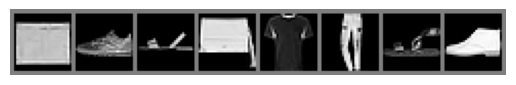

Bag | Sneaker | Sandal | Bag | T-shirt/top | Trouser | Sandal | Ankle boot


In [149]:
def image_print(img):
    img = (img / 2 )+ 0.5 # earlier i scaled the pixel values b/w -1 and 1 for good performance of cnn
                          # here i have scaled them back to being b/w 0 and 1 so that i can see the image clearly

    np_image = img.numpy()

    #i am plotting theimage

    plt.imshow(np.transpose(np_image, (1, 2,0)), cmap = 'gray')
    plt.axis('off') # This code hides the axis
    plt.show()

#getting images from data loader --

dataiter = iter(train_dataloader)
images, labels = next(dataiter)

# The code below draws a grid for the 8 images

image_print(torchvision.utils.make_grid(images[:8]))

#putting the classes i defined earlier on images 
print(' | '.join(f'{classes[labels[j]]}' for j in range(8)))

### Building the CNN

**Now i will create the cnn consisting of convolution, activation, pooling and dense layers**

In [150]:
class fashion_cnn(nn.Module): #with this, i have ineherited all functions and methods of nn.Module into the fashion_cnn class
    def __init__(self):
        super(fashion_cnn, self).__init__()

        # by the code below, i have initialized the first convolutional layer
        self.conv_layer_1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding =  1)

        #here i have created the first pooling layer which will half the image size (now becomes 14*14)
        self.pooling_layer_1 = nn.MaxPool2d(kernel_size=2, stride = 2)

        # creating the second conv layer
        self.conv_layer_2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding = 1)

        #creating the second pooling layer(again reduces the image size) - now becomes 7*7
        self.pooling_layer_2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # i started with 1 * 28 * 28 and now it has become 32 * 7 * 7

        #flattening and creating the first dense layer
        self.fc_1 = nn.Linear(in_features= 32*7*7, out_features=128)

        # final layer which shows the output
        self.fc_2 = nn.Linear(in_features=128, out_features=10)

    def forward(self, x):

        # input image goes to convolution layer1, which goes to relu and which at last goes to pooling L-1
        x = self.pooling_layer_1(F.relu(self.conv_layer_1(x)))

        # Now x goes to convolution layer2, which goes to relu and which at last goes to pooling L-2
        x = self.pooling_layer_2(F.relu(self.conv_layer_2(x)))

        #flattening
        x = x.view(-1, 32*7*7) #the -1 dimension is calculated automatically by pytorch

        # x is sent to dense layer 1
        x = F.relu(self.fc_1(x))

        # now i will send x to final output layer
        x = self.fc_2(x)
        return x

model_cnn = fashion_cnn().to(device) # model object is created and i have loaded it to cpu

**I have created the cnn and loaded it to my laptop's cpu**

**Now i will initialize the loss fn(for evaluating cnn) and the optimizer(this helps cnn to improve its performance)**

In [151]:
#initializing the loss function and optimizer

criterion = nn.CrossEntropyLoss() #the loss fn
optimizer = optim.Adam(model_cnn.parameters(), lr = 0.001)

### Training and Validating the CNN

**I will run the training and validation loop now**

In [152]:
# importing required libraries
import time

In [153]:
epochs = 5 

#here i have set the no of epochs [how many times cnn will look at the whole training data]

In [154]:
losses_during_training = []
losses_during_validation = []
validation_accuracies = []

#these lists will store the results of training the cnn

In [ ]:
# Now i am traning and validating on cpu for 5 epochs

for epoch in range(epochs):

    start_time = time.time()

    model_cnn.train() #this tells the model that its in learning-mode, this is important as some layers behave differently in testing and training modes

    train_loss_running = 0.0 # i have initialized the loss to 0 before every epoch

    for images, labels in train_dataloader:
        images, labels = images.to(device), labels.to(device) #images and labels are sent to same as cnn (my cpu)

        optimizer.zero_grad() #i have cleared out the old memory of optimizer here
        outputs = model_cnn(images) #here i ran a forward pass on images in traning data
        loss = criterion(outputs, labels) #loss is calculated here
        loss.backward() #back-propagation
        optimizer.step() #here weights are updated to imporve the performance of cnn model

        train_loss_running += loss.item() #loss added
    
    average_loss_in_training = train_loss_running / len(train_dataloader)
    losses_during_training.append(average_loss_in_training)

    #training part completed above

    #validating --

    model_cnn.eval() #model is now NOT in training mode

    validation_loss_running = 0.0
    correct_output = 0
    total_outputs = 0

    with torch.no_grad(): #i have stopped gradient tracking as no back-propagation occurs in validation 
        for images, labels in validation_dataloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model_cnn(images)
            loss = criterion(outputs, labels)
            validation_loss_running += loss.item()

            # I am calculating the accuracy obtained during validation now --
            _, predictions = torch.max(outputs, 1) #finds which index(among 10 indices) had the highest score for each image
            total_outputs += labels.size(0)
            correct_output += (predictions == labels).sum().item()

        #appending the average validation loss
        avg_validation_loss = validation_loss_running / len(validation_dataloader)
        losses_during_validation.append(avg_validation_loss)

        validation_accuracy = (correct_output / total_outputs) * 100
        validation_accuracies.append(validation_accuracy)

        time_taken_in_epoch = time.time() - start_time

        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Time taken = {time_taken_in_epoch}")
        print(f"Train Loss: {average_loss_in_training:.4f}") 
        print(f"Validation Loss: {avg_validation_loss:.4f}")
        print(f"Validation Accuracy: {validation_accuracy:.4f}")

print('Training done')

Epoch [1/5]
Time taken = 12.862186431884766
Train Loss: 0.4973
Validation Loss: 0.3577
Validation Accuracy: 87.4100
Epoch [2/5]
Time taken = 14.165520191192627
Train Loss: 0.3190
Validation Loss: 0.3226
Validation Accuracy: 88.1300
Epoch [3/5]
Time taken = 13.638550758361816
Train Loss: 0.2711
Validation Loss: 0.2811
Validation Accuracy: 89.6000


**Now i am plotting graph b/w training loss and validation loss**

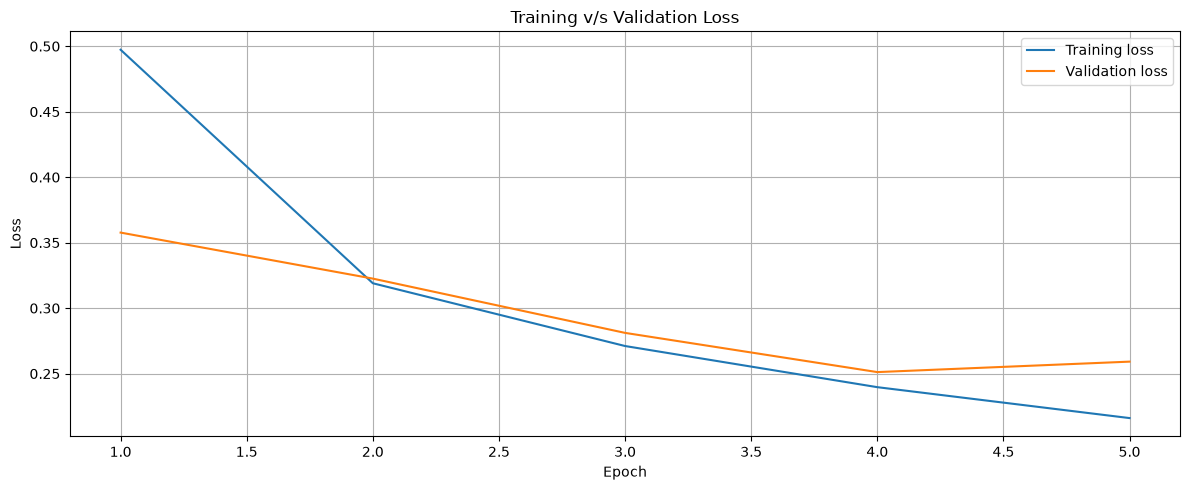

In [ ]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))
plt.plot(epochs_range, losses_during_training, label = 'Training loss')
plt.plot(epochs_range, losses_during_validation, label = "Validation loss")
plt.title("Training v/s Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Now i will plot how validation accuracy increases with epoch**

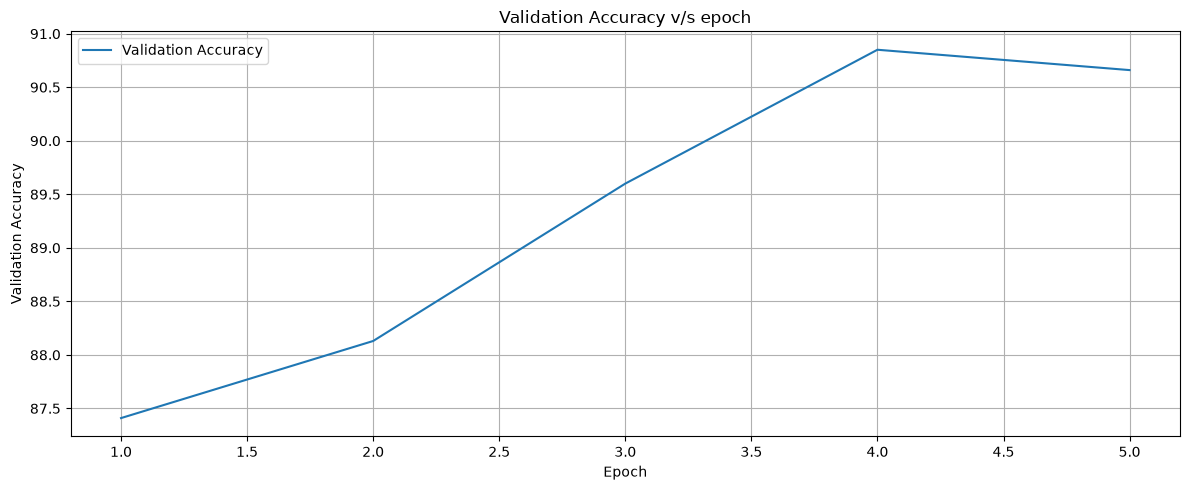

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(epochs_range, validation_accuracies, label = 'Validation Accuracy')
plt.title("Validation Accuracy v/s epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Observations from the 2 graphs --

**Training vs Validation Loss Graph:**
- Training loss decreased consistently from 0.497 (epoch 1) to 0.216 (epoch 5), showing that the CNN was learning well
- Validation loss also decreased from 0.358 to ~0.259, closely tracking the training loss
- Since the gap between training and validation loss is small and both are decreasing, there is no sign of overfitting
- However, at epoch 5 the validation loss (0.259) slightly increased compared to epoch 4 (0.251), which could indicate the very beginning of overfitting, training for many more epochs might cause this gap to widen

**Validation Accuracy Graph:**
- Validation accuracy increased from 87.41% (epoch 1) to 90.85% (epoch 4)
- At epoch 5, accuracy slightly dipped to 90.66%, consistent with the small validation loss increase
- The steepest improvement was between epoch 1 and epoch 3, after that the gains became smaller
- This suggests that 5 epochs is a reasonable training duration, though a few more epochs with a learning rate scheduler could help

### Testing the CNN

**Now the model will be evaluated on test data**

In [ ]:
model_cnn.eval() # model is now set to be in testing phase

fashion_cnn(
  (conv_layer_1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pooling_layer_1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_layer_2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pooling_layer_2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc_1): Linear(in_features=1568, out_features=128, bias=True)
  (fc_2): Linear(in_features=128, out_features=10, bias=True)
)

In [ ]:
#i have initialized the variables in this cell

running_test_loss = 0.0
total_correct_predictions_test = 0
total_predictions_test = 0

In [ ]:
with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)

        outputs = model_cnn(images)
        loss = criterion(outputs, labels)
        running_test_loss += loss.item()

        _, predictions = torch.max(outputs, 1)
        total_predictions_test += labels.size(0)
        total_correct_predictions_test += (predictions == labels).sum().item()
    
final_test_loss = running_test_loss / len(test_dataloader)
final_accuracy_test = (total_correct_predictions_test / total_predictions_test) * 100

print(f"Test Loss: {final_test_loss}")
print(f"Accuracy: {final_accuracy_test}")

Test Loss: 0.2752472637755096
Accuracy: 90.35


In [ ]:
# The code in the above cell is very similar to the code i wrote in validation, accuracy obtained = 89.8%

**Training, validation and testing of CNN done**

**Now i will pick up 5 correct predictions and 5 incorrect predictions**

In [ ]:
model_cnn.eval() #model is put in testing mode to pick out req. images

fashion_cnn(
  (conv_layer_1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pooling_layer_1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_layer_2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pooling_layer_2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc_1): Linear(in_features=1568, out_features=128, bias=True)
  (fc_2): Linear(in_features=128, out_features=10, bias=True)
)

In [ ]:
#initialing required lists

correct_images = [] 
correct_labels = []
correct_preds = []
incorrect_images = [] 
incorrect_preds = []
incorrect_labels = []

**The code below helps to take out 5 correct and 5 incorrect predictions**

In [ ]:
with torch.no_grad():
    for images, labels in test_dataloader:

        images, labels = images.to(device), labels.to(device)
        outputs = model_cnn(images)
        _, predictions = torch.max(outputs, 1)

        # i have stored the    predictions in predictions using torch.max

        images = images.cpu()
        labels = labels.cpu()
        predictions = predictions.cpu()


        for i in range(len(labels)):
            if predictions[i] == labels[i]:
                if len(correct_images) < 5:
                    correct_images.append(images[i])
                    correct_labels.append(labels[i])
                    correct_preds.append(predictions[i])
            else:

                if len(incorrect_images) < 5:
                    incorrect_images.append(images[i])
                    incorrect_labels.append(labels[i])
                    incorrect_preds.append(predictions[i])

            if len(correct_images) == 5 and len(incorrect_images) == 5:
                break

        if len(correct_images) == 5 and len(incorrect_images) == 5:
            break

**Now i will plot the images**

In [ ]:
def plotting_images(list_images, list_labels, list_predictions, title):

    plt.figure(figsize=(12, 5))
    plt.suptitle(title)

    for i in range(5):

        plt.subplot(1, 5, i+1)
        image = list_images[i] / 2 + 0.5  # Un-normalizing vals in [-1, 1] back to [0, 1]
        np_image = image.numpy()
        plt.imshow(np.transpose(np_image, (1, 2, 0)), cmap='gray')
        
        color = "green" if list_labels[i] == list_predictions[i] else "red"
        plt.title(f"True: {classes[list_labels[i]]}\nPred: {classes[list_predictions[i]]}", color=color)
        plt.axis('off') 
    
    plt.tight_layout()
    plt.show()

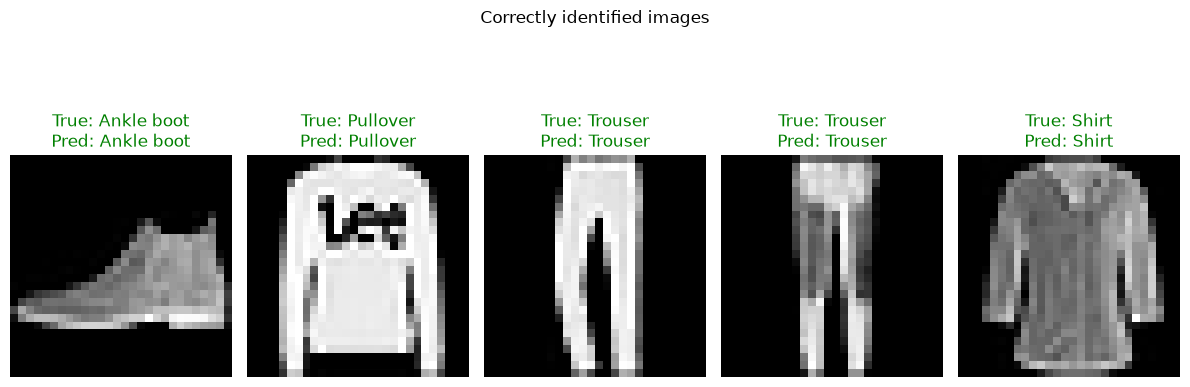

In [ ]:
# correct predictions --

plotting_images(correct_images, correct_labels, correct_preds, "Correctly identified images")

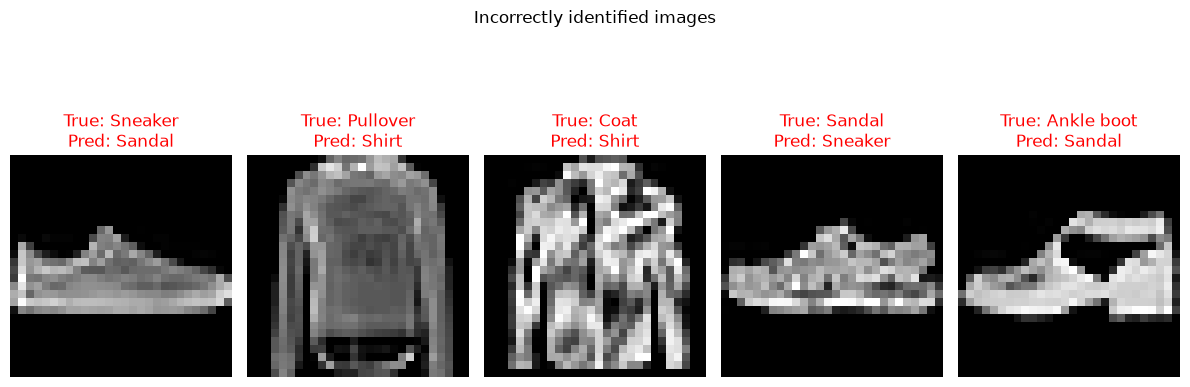

In [ ]:
# Incorrectly identified images --

plotting_images(incorrect_images, incorrect_labels, incorrect_preds, "Incorrectly identified images")

### Reasons behind incorrect predictions above


**Analysis of why the CNN made wrong predictions:**
1. **Shirt misclassified as T-shirt/top** — Shirts and T-shirts have very similar shapes in grayscale images. Both are upper-body garments with a similar overall silhouette. The main differences (collar type, buttons, fabric texture) are subtle details that are hard to capture in low-resolution 28x28 grayscale images. The CNN likely focused on the general shape (torso-shaped garment) and could not distinguish the finer details.
2. **Pullover misclassified as Coat** — Pullovers and coats share a very similar outline — both cover the torso and arms. The difference is usually in length, thickness, and texture, which are difficult to distinguish in small grayscale images. The CNN's convolutional filters may have picked up the same edge patterns for both categories.
3. **Shirt misclassified as Dress** — Some shirts, especially longer ones, can look similar to short dresses in a 28x28 image. When the garment extends below the waist in the image, the CNN may confuse the two categories because the overall shape becomes similar. The lack of color information (which in real life helps distinguish shirts from dresses) makes this even harder.
**Common pattern across all errors:** The CNN struggles most when two categories have similar shapes/silhouettes. Since it only sees grayscale 28x28 images, it cannot rely on color, texture details, or high-resolution features that humans use to distinguish these items. Most errors occur between visually similar upper-body garments (Shirt, T-shirt, Pullover, Coat).

- The major reason behind incorrect predictions above is that the actual label is very similar to predicted label in the image. So the model found it difficult to differentiate them.

### Reasoning Questions

#### q1 -- Why did you choose this advanced track?
- Answer = I chose Track A (CNN / Computer Vision) because image classification is one of the domains of advanced ai which i understood better as compared to others in the curriculum of summer school. Also apart from other domains, image classification was the domain in which i developed my interest and thus i wanted to work on this.

#### q2 -- What did the model learn or use to make predictions?
- Answer = The CNN learned to extract visual features from images through its convolutional layers. The first convolutional layer (16 filters) learned to detect basic features like edges, corners, and simple shapes. The second convolutional layer (32 filters) combined these basic features into more complex patterns like outlines of sleeves, collars, or shoe shapes. The pooling layers reduced the image size while keeping the most important features. Finally, the dense layers combined all these extracted features to make a classification decision among the 10 categories.

#### q3 -- What is one important limitation of your approach?
- Answer = One important limitation is the simplicity of the CNN architecture. With only 2 convolutional layers and no regularization techniques like dropout or batch normalization, the model's capacity to learn complex patterns is limited. Also,training on CPUfor only 5 epochs limited how much the model could learn.

#### q4 -- What would you improve if you had more data, compute or time?
- Answer = With more compute and time, I would: (1) Add more convolutional layers to create a deeper network that can learn more complex features, (2) Add dropout layers to prevent overfitting, (3) Add batch normalization for faster and more stable training, (4) Train for 20-30 epochs instead of 5, (5) Use a learning rate scheduler to reduce the learning rate as training progresses, (6) Try data augmentation (random flips, rotations, crops) to artificially increase the training data and make the model more robust, (7) Use GPU training for faster experimentation.
#### q5 -- Where could this model be used in a real application?
- Answer = This type of image classification model could be used in: (1) E-commerce platforms — automatically categorizing product images uploaded by sellers to organize them into the correct category, (2) Fashion recommendation systems — identifying the type of clothing in a user's photo and recommending similar items, (3) Inventory management — automatically scanning and categorizing clothing items in a warehouse, (4) Visual search — allowing users to take a photo of a clothing item and find similar products in an online store. In the real world, the model would need to be trained on higher resolution, color images with many more categories.


### Final Observations and Conclusions

- The CNN achieved 90.35% test accuracy on Fashion-MNIST, which is a good result for a simple 2-layer architecture trained for only 5 epochs
- Training and validation losses decreased together, showing no significant overfitting
- The model performs well on visually distinct categories (Trouser, Sneaker, Bag, Ankle Boot) but struggles with similar-looking categories (Shirt vs T-shirt, Pullover vs Coat)
- The confusion between visually similar clothing items is an expected limitation of small grayscale images — higher resolution and color images would help
- PyTorch provided a flexible framework for building the CNN from scratch, and understanding each component (Conv2d, MaxPool2d, ReLU, Linear layers) was a valuable learning experience
- The validation accuracy plateauing around 90% after epoch 4 suggests that deeper architectures and regularization would be needed to push accuracy further


# Learnings from this Capstone Project


- **Understanding the problem before the model**: EDA in Task 1 taught me that understanding data (class imbalance, correlations, outliers) is more important than jumping straight to model building. The insights from EDA directly influenced my model choices and preprocessing.
- **Metrics matter more than accuracy**: In Task 2, i learned that accuracy alone is misleading — especially for imbalanced datasets. Recall and the confusion matrix were far more important for evaluating the medical stroke prediction problem.
- **Feature engineering is crucial**: Proper encoding (OneHotEncoder for nominal features), scaling (StandardScaler), and preventing data leakage (fit on train, transform on test) are essential steps that directly impact model performance.
- **Redundant features can hurt**: Task 3 showed me that removing a redundant feature (`total_rooms`) actually slightly improved the model, teaching me that more features is not always better.
- **Clustering needs interpretation**: In Task 4, i learned that clustering is not just about forming groups — interpreting what each cluster represents in the real world is the most important part. The elbow method gives a starting point, but domain knowledge is needed to validate the clusters.
- **Deep learning fundamentals**: Task 5 gave me hands-on experience with building a CNN from scratch. I understood how convolution extracts features, how pooling reduces dimensions, how backpropagation updates weights, and why proper data normalization matters for neural networks.
- **End-to-end ML workflow**: This capstone taught me the complete workflow — from data loading and cleaning, through EDA, feature engineering, model training and evaluation, to interpretation and communication of results.

# THANK YOU :)